# Forecasting hourly bike rentals in Seoul

At the start of an hour, how accurately can the bike-share operator predict the number of rentals citywide? Does adding the rental count from one hour, one day and one week earlier improve on a calendar-only model? Calendar patterns can capture a regular evening peak. Recent counts might capture a quieter or busier day than usual.

The forecast covers the coming hour and assumes the count for the previous hour is already available. The outcome is completed rentals, including hours when the system was closed. The primary metric is **mean absolute error** in rentals per hour. An error of 100 means the prediction missed the observed count by 100 rentals on average.

## Data and forecast timing

The Seoul Bike Sharing Demand dataset records the number of public bike rentals each hour, along with weather, holiday and operating-status fields. It contains one citywide count per hour from December 2017 through November 2018. At prediction time the hour, weekday and holiday are known. Weather in this file was measured during the target hour, so the models use calendar information and past rental counts. The operating flag is used to describe closures. [Easwaramoorthy (2020), UCI Machine Learning Repository](https://doi.org/10.24432/C5F62R)

Run the notebook from the top with Python, pandas, NumPy, Matplotlib and scikit-learn in Jupyter. The first cell downloads the source from UCI. It can also read an original `SeoulBikeData.csv` placed beside the notebook.

In [1]:
from io import BytesIO
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

source_url = "https://archive.ics.uci.edu/static/public/560/seoul+bike+sharing+demand.zip"
csv_path = Path("SeoulBikeData.csv")
if csv_path.is_file():
	data = csv_path.read_bytes()
else:
	with urlopen(source_url, timeout=30) as response, ZipFile(BytesIO(response.read())) as archive:
		data = archive.read(csv_path.name)

raw = pd.read_csv(BytesIO(data), encoding="cp1252")
hours = pd.to_datetime(raw["Date"], format="%d/%m/%Y") + pd.to_timedelta(raw["Hour"], unit="h")
bikes = raw.set_index(hours).sort_index().rename_axis("time")
bikes = bikes.rename(columns={"Rented Bike Count": "rentals"})
assert bikes.index.equals(pd.date_range(bikes.index.min(), bikes.index.max(), freq="h"))
assert bikes[["rentals", "Holiday", "Functioning Day"]].notna().all().all()
assert bikes["rentals"].ge(0).all()
print(f"{len(bikes):,} consecutive hours from {bikes.index.min()} to {bikes.index.max()}.")

8,760 consecutive hours from 2017-12-01 00:00:00 to 2018-11-30 23:00:00.


## Chronological split

December through July supplies the training history. August and September form the validation period for comparing the models. October and November are reserved for the final evaluation. Each prediction uses the counts already observed by that hour. This allows an observed count from Monday to inform Tuesday's forecast even when both days fall in validation.

Each lag is formed on the complete, ordered hourly index. The first week lacks a weekly lag, so every model starts on the same date. Closure hours stay in the timeline because the system recorded zero completed rentals during those hours.

In [2]:
frame = bikes[["rentals"]].copy()
frame["hour_of_week"] = frame.index.day_of_week * 24 + frame.index.hour
frame["holiday"] = bikes["Holiday"]
lag_hours = [1, 24, 168]
lag_features = [f"lag_{hours_back}h" for hours_back in lag_hours]
for hours_back, column in zip(lag_hours, lag_features):
	frame[column] = frame["rentals"].shift(hours_back)

frame = frame.dropna(subset=lag_features)
train = frame.loc[frame.index < "2018-08-01"].copy()
valid = frame.loc[(frame.index >= "2018-08-01") & (frame.index < "2018-10-01")].copy()
test = frame.loc[frame.index >= "2018-10-01"].copy()
assert train.index.max() < valid.index.min() <= valid.index.max() < test.index.min()
assert len(train) + len(valid) + len(test) == len(bikes) - max(lag_hours)

splits = {"Training": train, "Validation": valid, "Final test": test}
pd.DataFrame([
	{
		"Split": name,
		"First day": rows.index.min().date(),
		"Last day": rows.index.max().date(),
		"Hourly forecasts": len(rows),
	}
	for name, rows in splits.items()
]).set_index("Split")

,First day,Last day,Hourly forecasts
Split,,,
Training,2017-12-08,2018-07-31,5664
Validation,2018-08-01,2018-09-30,1464
Final test,2018-10-01,2018-11-30,1464


## What patterns are visible in training?

The daily series shows how far demand moves across months. The hourly profiles compare weekdays and weekends, averaging observed rentals across all training dates in each group.

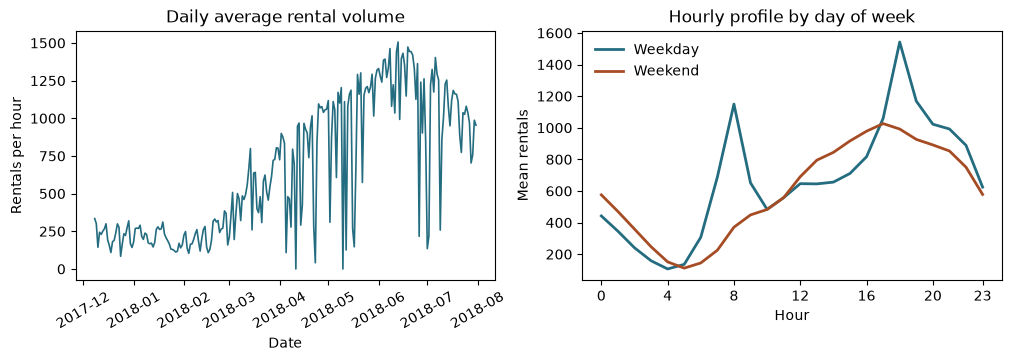

Closed training hours: 48 of 5,664.
Peak hour by day type: {'Weekday': 18, 'Weekend': 17}


In [3]:
daily_rentals = train["rentals"].resample("D").mean()
day_type = np.where(train.index.day_of_week < 5, "Weekday", "Weekend")
profile = train.groupby([train.index.hour, day_type])["rentals"].mean().unstack()

fig, (trend, hourly) = plt.subplots(1, 2, figsize=(10, 3.5), constrained_layout=True)
trend.plot(daily_rentals.index, daily_rentals, color="#246c80", linewidth=1.2)
trend.set(title="Daily average rental volume", ylabel="Rentals per hour", xlabel="Date")
trend.tick_params(axis="x", labelrotation=30)
for label, color in [("Weekday", "#246c80"), ("Weekend", "#a64c24")]:
	hourly.plot(profile.index, profile[label], label=label, color=color, linewidth=2)
hourly.set(title="Hourly profile by day of week", xlabel="Hour", ylabel="Mean rentals")
hourly.set_xticks([0, 4, 8, 12, 16, 20, 23])
hourly.legend(frameon=False)
plt.show()

closed = bikes.loc[train.index, "Functioning Day"].eq("No")
print(f"Closed training hours: {closed.sum()} of {len(train):,}.")
print("Peak hour by day type:", profile.idxmax().to_dict())

The weekday profile peaks at 18:00, one hour later than the weekend profile. The daily series also rises markedly from winter into summer. The same weekday and hour can therefore have different rental volumes across the training period.

## Three forecasts

The **previous-hour baseline** repeats the last observed count. It is a useful benchmark when demand changes gradually. The **calendar ridge regression** learns a separate effect for each of the 168 hours of the week and a holiday effect. The **calendar and history ridge regression** adds the three lagged counts. Comparing the two regressions isolates how much the observed history helps.

Both regressions use a fixed ridge penalty of 1. The penalty shrinks the fitted coefficients toward zero, and the numerical lag features are standardized using the training period. Predictions have a lower bound of zero because rental counts cannot be negative.

In [4]:
calendar_features = ["hour_of_week", "holiday"]


def rental_model(history_features: list[str]) -> Pipeline:
	"""Build a ridge regression for the calendar and the specified rental-count lags."""
	columns = ColumnTransformer([
		("calendar", OneHotEncoder(handle_unknown="ignore"), calendar_features),
		("history", StandardScaler(), history_features),
	])
	return make_pipeline(columns, Ridge(alpha=1.0, solver="lsqr"))


models = {
	"Calendar ridge": rental_model([]),
	"Calendar + history ridge": rental_model(lag_features),
}
predictors = calendar_features + lag_features
for model in models.values():
	model.fit(train[predictors], train["rentals"])

## Validation results

All three methods predict the same hours. Each hour has equal weight. A lower mean absolute error means fewer rentals missed per forecast on average.

In [5]:
valid_predictions = pd.DataFrame({"Previous hour": valid["lag_1h"]}, index=valid.index)
for name, model in models.items():
	valid_predictions[name] = np.maximum(0, model.predict(valid[predictors]))

validation_mae = valid_predictions.apply(lambda pred: mean_absolute_error(valid["rentals"], pred))
validation_mae.rename("Mean absolute error (rentals/hour)").round(1).to_frame()

,Mean absolute error (rentals/hour)
Previous hour,220.0
Calendar ridge,440.6
Calendar + history ridge,136.0


On validation, adding the three historical counts reduced mean absolute error from 440.6 to 136.0 rentals per hour. Even repeating the last count (220.0) beat the calendar model. The combined model also beat that baseline by 84.0 rentals per hour. The comparison measures the contribution of the three lags together across August and September.

## Handoff for the final evaluation

`train`, `valid` and `test` contain the same target and predictors. `valid_predictions` has one row per forecast hour and a column per method. Once the group settles on its models, refit on training plus validation and evaluate all three on the same October–November hours. Report the overall error and check where the previous-hour forecast and the history regression differ most. The final test results, comparison with related work and presentation are the remaining group tasks.